In [1]:
# origin: https://github.com/SiyuanYan1/PanDerm
import timm

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [1]:
!nvidia-smi

Fri Oct 23 11:53:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA H100 PCIe               On  |   00000000:B5:00.0 Off |                    0 |
| N/A   49C    P0             94W /  350W |   26149MiB /  81559MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [2]:
import torch
import torchvision
import os
from os.path import join as j_
from PIL import Image
import numpy as np
from torch import nn
from torchvision import datasets, transforms
# loading all packages here to start
from panderm_model import get_encoder
from torchvision.transforms import InterpolationMode

In [3]:
import sys, importlib
import os

for path in ["script", "..", "../.."]:
    path = os.path.abspath(path)
    if path not in sys.path:
        sys.path.append(path)


In [4]:
# Augmentation Scheme Loop
import Datasets.MILK_10K.augmentation_scheme_image
import importlib
importlib.reload(Datasets.MILK_10K.augmentation_scheme_image)

from Datasets.MILK_10K.augmentation_scheme_image import _augmentation_gpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [5]:
# # does not work 
# from models import get_encoder
# model_name='PanDerm'
# model, eval_transform = get_encoder(model_name)

In [5]:
from models.modeling_finetune import VisionTransformer
from functools import partial

/usr/local/lib/python3.10/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.10/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)


In [8]:
# manual model load: vit-large original
model = VisionTransformer(
    patch_size=16,embed_dim=1024,depth=24,num_heads=16,
    mlp_ratio=4,qkv_bias=True,norm_layer=partial(nn.LayerNorm, eps=1e-6),)

# weight_l = torch.load('checks/panderm_ll_data6_checkpoint-499.pth')
ckpt = torch.load(
    "checks/panderm_ll_data6_checkpoint-499.pth",
    map_location="cpu")

encoder_state = {
    k[len("encoder."):]: v
    for k, v in ckpt.items()
    if k.startswith("encoder.")}

msg = model.load_state_dict(
    encoder_state, strict=False)

print("Missing:", msg.missing_keys)
print("Unexpected:", msg.unexpected_keys)

/usr/local/lib/python3.10/dist-packages/torch/functional.py:534: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /opt/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:3593.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


In [11]:
# manual model load: vit-base original
model = VisionTransformer(
        patch_size=16, embed_dim=768, depth=12, num_heads=12, mlp_ratio=4, qkv_bias=True,
        norm_layer=partial(nn.LayerNorm, eps=1e-6), drop_path_rate= 0.1) # modified on drop_path_rate initially 0.1

# vit-base manual weight load
model.load_state_dict(torch.load('checks/panderm_bb_data6_checkpoint-499.pth', map_location='cpu'), strict=False) 

/scratch/26228052/ipykernel_3937874/244305902.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('checks/panderm_bb_data6_checkpoint-499.pt

_IncompatibleKeys(missing_keys=['head.weight', 'head.bias'], unexpected_keys=[])

In [6]:
# custom model 
# getting the fine tuned model
import script.custom_models.panderm_custom_classifier
import importlib
from geom_hyp import lorentz as L
from geom_hyp import manifold_conversion as MC
importlib.reload(script.custom_models.panderm_custom_classifier)
from script.custom_models.panderm_custom_classifier import PanDermWithHead, PanDermWithHypHead


/usr/local/lib/python3.10/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.10/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)


In [7]:
model = PanDermWithHead(10, model_type= 'base')
# model.visual.model.blocks[0].attn.qkv.weight #sanity check

/usr/local/lib/python3.10/dist-packages/torch/functional.py:534: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /opt/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:3593.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/user/zahidhas/FM_Skin_Cancer/SkinFM_med/PanDerm/classification/script/custom_models/panderm_custom_classifier.py:70: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loa

In [7]:

# model manual checking 
print("hyperbolic head model")
results = torch.load("../../Datasets/sarker_embeddingDerm12345 datasets_64.pt")
z_p = results["data"]  # torch.Tensor
z_l = MC.poincare_to_lorentz(z_p) # lorentz points
# data loader 
z_l[:,1:].shape

# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = PanDermWithHypHead(64, l_target= z_l[0:40,1:].to(device), multilayer= True) # lorentz space components

# model = DermLIPWithHead(11) # Euclidean model

# Weight loading
# PATH = 'weights_local/DermLIP_hyper_head_clinical_dermoscopic_weight.pth'

PATH  = '../../../../../../projects/academic/sangst/zahidhas/Model_Weights/PanDerm/PanDerm_hyper_sarkar_head_64_Derm12345_weight_ce_multilayer_small_radius_2.pth'


checkpoint = torch.load(PATH, map_location=device)
missing, unexpected = model.load_state_dict(checkpoint['model_state_dict'],  strict=False)
print(f"Missing: {missing}")
print(f"Unexpected: {unexpected}")

hyperbolic head model


/scratch/26548222/ipykernel_887945/1983508411.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  results = torch.load("../../Datasets/sarker_embeddingDerm12345 datasets_64.

Missing: []
Unexpected: []


In [7]:
model.blocks[0].attn.qkv.weight

Parameter containing:
tensor([[ 4.0056e-03, -1.5391e-03,  9.6795e-03,  ...,  1.1216e-02,
         -2.6755e-02,  6.2660e-02],
        [ 1.2443e-02, -2.5274e-04,  1.0965e-02,  ..., -8.0123e-04,
          2.1772e-02,  5.3987e-03],
        [ 1.3365e-01,  1.0408e-02, -8.6675e-02,  ..., -2.5417e-02,
          3.4505e-02, -1.1168e-01],
        ...,
        [ 3.7740e-03,  7.9692e-04,  3.9547e-05,  ..., -2.8499e-02,
          2.2767e-02,  1.3238e-02],
        [-3.1710e-03,  1.6321e-03, -1.0645e-03,  ..., -6.0301e-03,
          5.3892e-02,  1.7964e-02],
        [-1.7574e-03,  1.2415e-03,  2.1553e-03,  ..., -6.6115e-02,
          5.7944e-02, -2.6193e-02]], requires_grad=True)

In [8]:
# data loading. 

import sys, importlib
path_to_root = os.path.abspath(os.path.join('..'))
if path_to_root not in sys.path:
    sys.path.append(path_to_root)

import Datasets.MILK_10K.Milk10_dataset_loader 
import Datasets.isic_kaggle_2016.IsicKaggle2016
import Datasets.fitzpatrick17k.fitzpatrick_data_loader

importlib.reload(Datasets.MILK_10K.Milk10_dataset_loader)

from Datasets.MILK_10K.Milk10_dataset_loader import MILK10kDataset, get_image_transform
from Datasets.isic_kaggle_2016.IsicKaggle2016 import TumorDataset
from Datasets.fitzpatrick17k.fitzpatrick_data_loader import Fitz17kDataset

# Derm12345 loading

path_to_root = os.path.abspath(os.path.join('../../../../../../projects/academic/sangst/zahidhas/Datasets'))
if path_to_root not in sys.path:
    sys.path.append(path_to_root)

from DERM12345.derm12345_data_loader import DERM12345Dataset


# ISIC loading
from isic_2019.isic_2016_dataset_loader import ISIC2019Dataset


In [9]:
im_size = 224

transform_train_no_np = transforms.Compose([
    transforms.Resize((im_size, im_size),  interpolation=InterpolationMode.BICUBIC),  # Resize the image
    transforms.PILToTensor()  # Convert to uint8 tensor array [c, h, w]
])

In [10]:
# ISIC 2019 datasets
root = "../../../../../../projects/academic/sangst/zahidhas/Datasets/isic_2019"

dataset_keep_track = "Isic2019 datasets"

img_size = 224

train_dataset = ISIC2019Dataset(
    root=root,
    split="test",
    image_transform=get_image_transform('train', img_size=img_size),
    balanced=False,
    seed=44,
)

In [17]:
# MILK 10K dataset
dataset_keep_track = "MILK 10K datasets"
print(dataset_keep_track)

root             = '../../Datasets/MILK_10K/Train'
split            = 'train'

train_dataset =  MILK10kDataset(
        root             = root, 
        split            = split,
        image_transform  = get_image_transform(split, im_size),
        balanced         = False,
        seed             = 44,)

MILK 10K datasets


In [15]:
# FitzPatrick dataset
dataset_keep_track = "Fitzpatrick datasets"
print(dataset_keep_track)

root             = '../../Datasets/fitzpatrick17k/'
csv_file = "fitzpatrick17k.csv"

img_size = 224

train_dataset =  Fitz17kDataset(
        root             = root,
        csv_file         = csv_file,
        image_transform  = get_image_transform("train", img_size),
    )

Fitzpatrick datasets


In [10]:
# Derm12345 dataset
dataset_keep_track = "Derm12345 datasets"
print(dataset_keep_track)

root             = "../../../../../../projects/academic/sangst/zahidhas/Datasets/DERM12345/"

img_size = 224

train_dataset  = DERM12345Dataset(
        root=root,
        split="test",
        image_transform=get_image_transform("train", img_size = img_size),
        target_col="label",
        balanced=False,
        seed=44,
    )

Derm12345 datasets


In [11]:
# common path begins HERE
print(dataset_keep_track)
im, label = train_dataset[0]

from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,persistent_workers=False,
)

Derm12345 datasets


In [12]:
#%% iteration over the dataset
print(dataset_keep_track)

loader_iter = iter(train_loader)
images, labels = next(loader_iter)

Derm12345 datasets


In [13]:
constants_zoo = {
    'imagenet': {'mean': (0.485, 0.456, 0.406), 'std': (0.228, 0.224, 0.225)},
    'openai_clip':{'mean': (0.48145466, 0.4578275, 0.40821073), 'std': (0.26862954, 0.26130258, 0.27577711)},
    'uniform': {'mean': (0.5, 0.5, 0.5), 'std': (0.5, 0.5, 0.5)}
}
constants = constants_zoo['openai_clip']

mean, std = constants.get('mean'), constants.get('std')
dl_preprocess = transforms.Compose([
    transforms.Normalize(mean=mean, 
                         std=std),
])

In [14]:
loader_iter = iter(train_loader)
images, labels = next(loader_iter)

if dataset_keep_track == "MILK 10K datasets":
    type_image = images['dermoscopic']
    input_image = dl_preprocess(type_image/255.0)
    print(dataset_keep_track)
elif dataset_keep_track in ["ISIC 2016 datasets", 'Fitzpatrick datasets', "Derm12345 datasets", "Isic2019 datasets"]:
    type_image = images
    input_image = dl_preprocess(type_image/255.0)
    print(dataset_keep_track)

Derm12345 datasets


In [15]:
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = model.to(device)
model.eval()
    
print("Panderm VIT ONLY")
print(dataset_keep_track)

for _ in range(1):

    images, labels = next(loader_iter)

    if dataset_keep_track == "MILK 10K datasets":
        type_image = images['dermoscopic']
    elif dataset_keep_track in ["ISIC 2016 datasets", 'Fitzpatrick datasets', "Derm12345 datasets", "Isic2019 datasets"]:
        type_image = images

    
    input_image = dl_preprocess(type_image/255.0)
    input_image = input_image.to(device)
    
    with torch.no_grad():
        
        # o = model.visual(input_image)
        
        # oupt_list, labs1 = [], []
        # labs2 = []
        # oupt_list.append(o.cpu())
        # # labs1.append(labels['metadata']['dermoscopic_image_type'])
        # labs2.append(labels['class_index'])


        
        # model= model.visual.model

        x = model.patch_embed(input_image)
        batch_size, seq_len, _ = x.size()
    
        cls_tokens = model.cls_token.expand(batch_size, -1, -1)  # stole cls_tokens impl from Phil Wang, thanks
        x = torch.cat((cls_tokens, x), dim=1)
        if model.pos_embed is not None:
            x = x + model.pos_embed.expand(batch_size, -1, -1).type_as(x).to(x.device).clone().detach()
    
        x = model.pos_drop(x)
    
        rel_pos_bias = model.rel_pos_bias() if model.rel_pos_bias is not None else None
        i = 0
        for blk in model.blocks[0:-1]:
            x = blk(x, rel_pos_bias=rel_pos_bias)
    
            print(i)
            i += 1
    
        # got the final attention stage (find the attention map)
        blk = model.blocks[-1]
    
    
    
        # blk attn start.  blk.attn(blk.norm1(x), rel_pos_bias=rel_pos_bias) equvalence
        fin_attn = blk.attn
        x1 = blk.norm1(x)
    
    
    
        B, N, C = x1.shape
        qkv_bias = None
        if fin_attn.q_bias is not None:
            qkv_bias = torch.cat((fin_attn.q_bias, torch.zeros_like(fin_attn.v_bias, requires_grad=False), fin_attn.v_bias))
        qkv = F.linear(input=x1, weight=fin_attn.qkv.weight, bias=qkv_bias)
        qkv = qkv.reshape(B, N, 3, fin_attn.num_heads, -1).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]   # make torchscript happy (cannot use tensor as tuple)
    
        q = q * fin_attn.scale
        attn = (q @ k.transpose(-2, -1))
    
        if fin_attn.relative_position_bias_table is not None:
            relative_position_bias = \
                fin_attn.relative_position_bias_table[fin_attn.relative_position_index.view(-1)].view(
                    fin_attn.window_size[0] * fin_attn.window_size[1] + 1,
                    fin_attn.window_size[0] * fin_attn.window_size[1] + 1, -1)  # Wh*Ww,Wh*Ww,nH
            relative_position_bias = relative_position_bias.permute(2, 0, 1).contiguous()  # nH, Wh*Ww, Wh*Ww
            attn = attn + relative_position_bias.unsqueeze(0)
    
        if rel_pos_bias is not None:
            attn = attn + rel_pos_bias
    
        attn = attn.softmax(dim=-1)
        attn = fin_attn.attn_drop(attn)
    
        x1 = (attn @ v).transpose(1, 2).reshape(B, N, -1)
        x1 = fin_attn.proj(x1)
        x1 = fin_attn.proj_drop(x1)
    
        ## blk attn end
        # equ
    
        x = x + blk.drop_path(blk.gamma_1 * x1) # x1 = blk.attn(blk.norm1(x), rel_pos_bias=rel_pos_bias)
        x = x + blk.drop_path(blk.gamma_2 * blk.mlp(blk.norm2(x)))
    
        tokens = model.norm(x)

# o[6] - tokens[6, 0] # idential

Using device: cuda
Panderm VIT ONLY
Derm12345 datasets
0
1
2
3
4
5
6
7
8
9
10


In [43]:
# flat_labels = [item for item in labs1 for _ in range(32)] # for milk meta information
# len(flat_labels)
try: 
    flat_labels = torch.cat(labs2, dim = 0)
except:
    flat_labels = [label for batch in labs2 for label in batch]

oupt = torch.cat(oupt_list, dim = 0)
len(flat_labels)
# one_hot_labels = F.one_hot(flat_labels.long(), num_classes= 11)

3872

In [44]:
#further 
print("Hyperbolic head model")
from geom_hyp import lorentz as L

mul_factor= 1

def clip_safe(input_vector, r):
    norms = torch.norm(input_vector, dim=-1, keepdim=True).clamp(min=1e-8)
    return input_vector * (float(r) / norms).clamp(max=1)

with torch.no_grad():
    image_feats = model.clf_head(oupt.to(device)) # projection head

    image_feats = image_feats * model.visual_alpha.exp() * mul_factor
    # clipping hyperbolic tangent vector
    image_feats = clip_safe(image_feats, model.clip_value) 
    # exponential mapping
    with torch.autocast(model.device.type, dtype=torch.float32):
        image_feats_h = L.exp_map0(image_feats, model.curv.exp())

    # _a, _d, _ah = L.oxy_angle_dist(image_feats_h, model.l_target, flat_labels, min_radius= 0.1)

Hyperbolic head model


In [45]:

with torch.no_grad():
    _a, _d, _ah = L.oxy_dist_angle_no_label(image_feats_h, model.l_target, min_radius= 0.1)

    image_logits = - _d * 2
    
    angle_min = _a.min(dim = -1) # return values and indices
    dist_min = (_d).min(dim = -1) # return values and indices
    
    
    # _d.shape
    # labels_idx = flat_labels.long()
    # selected_scores = _d[torch.arange(_d.size(0), device=_d.device), labels_idx]
    # selected_scores = _d.min(dim = -1)

In [66]:
# ignoring any class we want
ignore_classes = torch.tensor([8], device=flat_labels.device) 
keep = ~torch.isin(flat_labels, ignore_classes)
sum(keep)

tensor(2866)

In [22]:
unique_labels = sorted(list(set(flat_labels))) 
num_classes = len(unique_labels)

# 2. Create the mapping on the fly
label_to_idx = {name: i for i, name in enumerate(unique_labels)}

# 3. Convert and Encode
indices = torch.tensor([label_to_idx[l] for l in flat_labels])
one_hot = F.one_hot(indices, num_classes=num_classes)

NameError: name 'flat_labels' is not defined

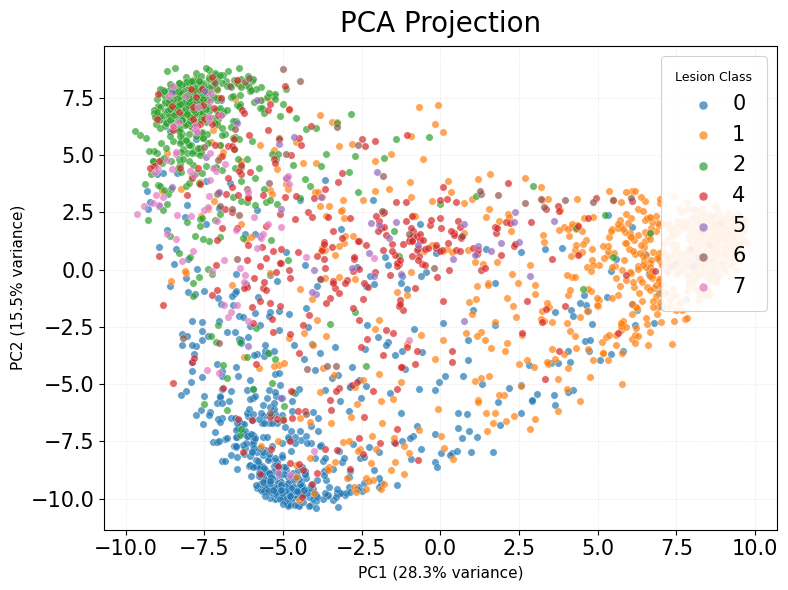

In [59]:
# [flat_labels[i] for i in clusters[1]]
import utils_external.plot_helper_visual as plot_helper_visual 
importlib.reload(plot_helper_visual)# Reload 
plot_pca_clusters = plot_helper_visual.plot_pca_clusters


import numpy as np
plot_pca_clusters (oupt[keep], flat_labels[keep], name = None)

# labels['class_vector'].shape

In [67]:
import utils_external.classification_metrics as accuracy_mat
importlib.reload(accuracy_mat)
multiclass_metrics = accuracy_mat.multiclass_metrics
correct_wrong_indices = accuracy_mat.correct_wrong_indices
import utils_external.hierarchy_matrics as hierarchy 
importlib.reload(hierarchy)# Reload 
hierarchical_metrics = hierarchy.hierarchical_metrics # Extract the updated function from the reloaded module

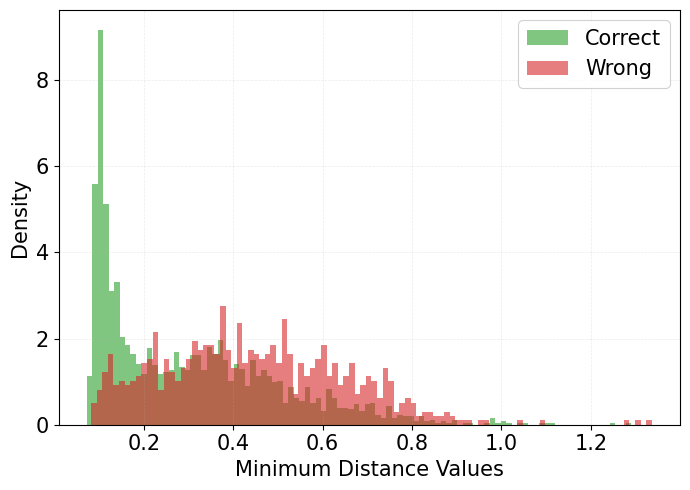

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns

cls_wrong = correct_wrong_indices(image_logits[keep], flat_labels[keep])
wrong_idx = cls_wrong["wrong_sample_indices"].to(oupt.device)
correct_idx = cls_wrong["correct_sample_indices"].to(oupt.device)

wrong_length = dist_min.values[keep][wrong_idx]#.norm(dim=-1)
correct_length = dist_min.values[keep][correct_idx]#.norm(dim=-1)


# wrong_length = image_feats[keep][correct_idx].norm(dim=-1)
# correct_length = image_feats[keep][wrong_idx].norm(dim=-1)


# wrong_length = oupt[0:960].norm(dim=-1)
# correct_length = oupt[960:].norm(dim=-1)

wrong_values = wrong_length.detach().cpu().numpy()
correct_values = correct_length.detach().cpu().numpy()


plot_norm_dist(correct_values, wrong_values, 'panderm_isic0219_cor_wrong_dist.svg')

Direction       : x1 <= threshold
AUROC           : 0.7099
Best threshold  : 0.213083
TPR             : 0.4477
FPR             : 0.1333
Youden's J      : 0.3144


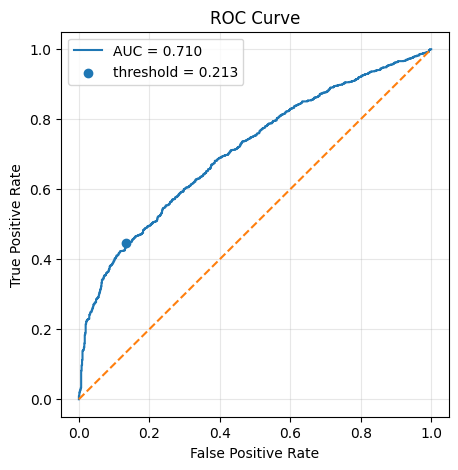

{'auc': 0.7098947193745851,
 'threshold': 0.21308279,
 'direction': 'x1 <= threshold',
 'tpr': 0.4477468839884947,
 'fpr': 0.13333333333333333,
 'youden_j': 0.3144135506551614}

In [74]:
from utils_external.classification_metrics import roc_separation
roc_separation(correct_length, wrong_length)

In [72]:
def plot_norm_dist(correct, wrong, name="feature_norm_distribution.svg", bins=100):
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.hist(correct, bins=bins, density=True, alpha=0.6, color="tab:green", label="Correct")
    ax.hist(wrong, bins=bins, density=True, alpha=0.6, color="tab:red", label="Wrong")
    ax.set_xlabel(r"Minimum Distance Values", fontsize=15)
    ax.set_ylabel("Density", fontsize=15)
    leg = ax.legend(loc="upper right", fontsize=15, frameon=True, framealpha=0.9)
    leg.get_frame().set_linewidth(0.8)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.25)
    ax.tick_params(axis="both", labelsize=15)
    plt.tight_layout()
    if name is not None:
        plt.savefig(name, format="svg", bbox_inches="tight")
    plt.show()

In [63]:
result = multiclass_metrics(image_logits[keep], flat_labels[keep],  topk = [3])
result

{'accuracy': 0.7512032580525732,
 'balanced_accuracy': 0.5590572642641334,
 'macro_f1': 0.5208139672173718,
 'weighted_f1': 0.7518267036464373,
 'classwise_f1': tensor([0.7326, 0.8562, 0.7713, 0.0000, 0.5583, 0.5246, 0.4286, 0.2950, 0.0000],
        dtype=torch.float64),
 'classwise_precision': tensor([0.7508, 0.8443, 0.7041, 0.0000, 0.7192, 0.8000, 0.8000, 0.4364, 0.0000],
        dtype=torch.float64),
 'classwise_recall': tensor([0.7152, 0.8684, 0.8526, 0.0000, 0.4562, 0.3902, 0.2927, 0.3380, 0.0000],
        dtype=torch.float64),
 'confusion_matrix': tensor([[ 452,  110,   28,   13,   24,    0,    1,    4,    0],
         [  73, 1003,   40,   15,   15,    0,    0,    9,    0],
         [  20,   13,  376,   12,    9,    1,    2,    8,    0],
         [   0,    0,    0,    0,    0,    0,    0,    0,    0],
         [  44,   47,   41,   32,  146,    3,    0,    7,    0],
         [   2,   10,    9,    3,    1,   16,    0,    0,    0],
         [   8,    5,   11,    0,    2,    0,   12,

In [64]:
from Datasets.label_details import get_hierarchy
TREE, NODES, _ = get_hierarchy("isic2019") # milk10k, isic2019, derm12345

In [65]:
topk=3
h_metrics = hierarchical_metrics(
    output=image_logits[keep],       # [N, number_of_leaves]
    labels=flat_labels[keep],  # [N]
    tree=TREE,
    nodes=NODES,
    topk= topk,)

print(h_metrics["mistake_severity"])
print(h_metrics["hierarchical_distance_top_" + str(topk)])
print(h_metrics["accuracy_at_depth"]) # h_metrics.keys()

2.684523820877075
1.5521411895751953
{0: 1.0, 1: 0.8159940838813782, 2: 0.7649019360542297, 3: 0.7512032985687256}


In [31]:
one_hot_labels = F.one_hot(flat_labels.long(), num_classes= 9)

In [33]:
# similiarity svcca, mutual information. 
# code source https://github.com/minyoungg/platonic-rep/blob/main/metrics.py
from utils_external.metrics_platonic import AlignmentMetrics
print(AlignmentMetrics.svcca(image_feats[keep], one_hot_labels.float()[keep], 7)) # or  flat_labels = one_hot.float() 


0.5715653815070106


In [41]:
# Gromov hyperbolicity test
def delta_hyp_torch(dismat):
    p = 0
    row = dismat[p, :][None, :]
    col = dismat[:, p][:, None]
    XY_p = 0.5 * (row + col - dismat)
    maxmin = torch.minimum(XY_p[:, :, None], XY_p[None, :, :]).max(1).values
    return (maxmin - XY_p).max()
import numpy as np

idx = np.random.choice(len(oupt), 1000)
# all_features_small = oupt[idx]

all_features_small = image_feats_h[idx]
# Euclidean distance similarity
# dists = torch.cdist(all_features_small, all_features_small)

# Lorentz distance similarity
dists = L.pairwise_dist(all_features_small, all_features_small)

delta = delta_hyp_torch(dists)
diam = torch.max(dists)
del_rel =  2*delta/diam
print('delta relative: ', del_rel)
c = (0.144 / del_rel) ** 2
print('c value: ', c)

delta relative:  tensor(0.2998, device='cuda:0')
c value:  tensor(0.2307, device='cuda:0')


In [31]:
from utils_external import metrics_platonic

ModuleNotFoundError: No module named 'torchaudio'

In [25]:
cls_attn = attn[:, :, 0, 1:]   # [B, 12, 196]
cls_attn = cls_attn.mean(dim=1)
# cls_attn = cls_attn[1]
B = cls_attn.shape[0]
mask = cls_attn.reshape(B, 14, 14)
attn.shape

torch.Size([32, 12, 197, 197])

In [26]:
mask = mask ** 0.8

In [30]:
# image points connection 
image_feats = tokens[:, 1:, :] # bs, no_feats (196), feat_dim 

def cosine_affinity(features: torch.Tensor, eps: float = 1e-8) -> torch.Tensor:
    """
    Args:    features: [B, N, D]
    Returns: affinity: [B, N, N]
    """
    features = F.normalize(features, p=2, dim=-1, eps=eps)
    # [B, N, D] @ [B, D, N] -> [B, N, N]
    affinity = torch.bmm(features, features.transpose(1, 2))
    affinity = (affinity+ 1)/2
    return affinity

def exponential_affinity(
    features: torch.Tensor, temperature: float = 1.0,
    eps: float = 1e-6) -> torch.Tensor:
    """
    Args:        features: [B, N, D]
    Returns:        affinity: [B, N, N]
    """
    # Pairwise Euclidean distances: [B, N, N]
    distances = torch.cdist(features, features, p=2)
    # affinity = 1.0 / (1.0 + distances)    # Stable inverse-distance similarity
    affinity = torch.exp(-distances / temperature) # RBF affinity
    return affinity

features = image_feats 

affinity_cosine = cosine_affinity(features)
# affinity_cosine = exponential_affinity(features, 3)

print(affinity_cosine.shape)

torch.Size([32, 196, 196])


In [32]:
import torch
from utils_external.spec_clus_ng import spectral_cluster


labels = spectral_cluster(
    affinity_cosine,   # [B, 196, 196]
    n_clusters= 3
)

print(labels.shape)
mask = labels.reshape(B, 14, 14).float()
# [B, 196]

torch.Size([32, 196])


In [33]:
mask = F.interpolate(
    mask.unsqueeze(1),      # [B,1,14,14]
    size=(224,224),
    mode='bilinear',
    align_corners=False
)

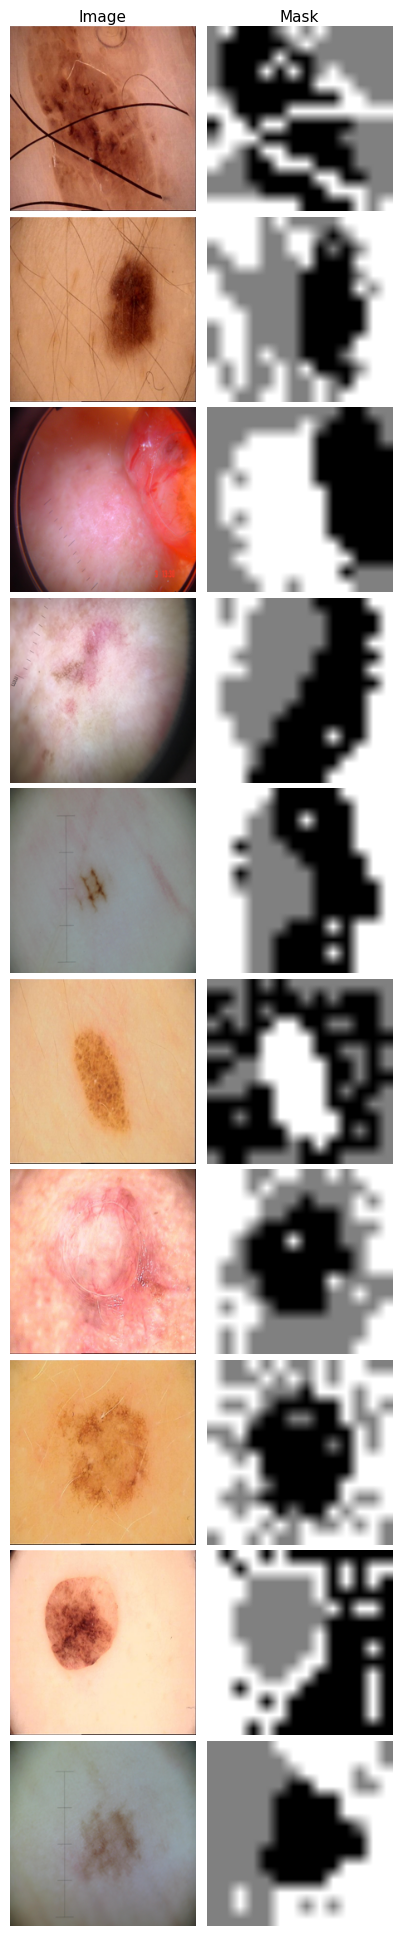

In [34]:
import matplotlib.pyplot as plt

n = 10

fig, axes = plt.subplots(
    n,
    2,
    figsize=(4, 2 * n),
    gridspec_kw={
        "wspace": 0.01,
        "hspace": 0.03
    }
)

for i in range(n):
    img = type_image[i].detach().permute(1, 2, 0).cpu()
    mask_img = mask[i, 0].detach().cpu()

    axes[i, 0].imshow(img)
    axes[i, 1].imshow(mask_img, cmap="gray")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

# Only one pair of headings
axes[0, 0].set_title("Image", fontsize=11, pad=3)
axes[0, 1].set_title("Mask", fontsize=11, pad=3)

plt.subplots_adjust(
    left=0.01,
    right=0.99,
    top=0.96,
    bottom=0.01,
    wspace=0.01,
    hspace=0.03
)

plt.savefig(
    "../../Figures_Saved/derm1m_Panderm_FT_cluster2.svg",
    format="svg",
    bbox_inches="tight",
    pad_inches=0.01
)

plt.show()

In [52]:
mask.min()

tensor(0)

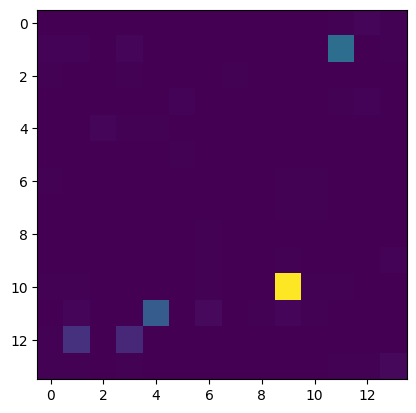

In [94]:
cls_attn = attn[:, :, 0, 1:]
cls_attn = cls_attn[:,8,:]
B = cls_attn.shape[0]
bs_pos = 2
mask1 = cls_attn.reshape(B, 14, 14)
plt.imshow(mask1[bs_pos])

In [68]:
fin_attn = blk.attn
fin_attn.qkv.weight

Parameter containing:
tensor([[-0.0351,  0.0446,  0.0129,  ..., -0.0042,  0.0786,  0.0191],
        [ 0.0564, -0.0280, -0.0070,  ...,  0.0025, -0.0406, -0.0095],
        [-0.0068, -0.0646,  0.0464,  ..., -0.0137,  0.0179,  0.0231],
        ...,
        [-0.0055,  0.0940, -0.0162,  ...,  0.0386,  0.0258,  0.0032],
        [-0.0255, -0.0586,  0.0436,  ..., -0.0086, -0.0374, -0.0098],
        [-0.0206, -0.0130, -0.0504,  ..., -0.0416, -0.0345, -0.0043]],
       requires_grad=True)

In [18]:
tokens =  tokens[:,1:,:]
B, N, D = tokens.shape
H = W = int(N ** 0.5)   # 14

feat_map = tokens.transpose(1, 2).reshape(B, D, H, W)

In [19]:
feat_map.shape

torch.Size([4, 768, 14, 14])

In [20]:
blk

Block(
  (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
  (attn): Attention(
    (qkv): Linear(in_features=768, out_features=2304, bias=False)
    (attn_drop): Dropout(p=0.0, inplace=False)
    (proj): Linear(in_features=768, out_features=768, bias=True)
    (proj_drop): Dropout(p=0.0, inplace=False)
  )
  (drop_path): DropPath(p=0.10000000149011612)
  (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
  (mlp): Mlp(
    (fc1): Linear(in_features=768, out_features=3072, bias=True)
    (act): GELU(approximate='none')
    (fc2): Linear(in_features=3072, out_features=768, bias=True)
    (drop): Dropout(p=0.0, inplace=False)
  )
)

In [21]:
blk.attn.qkv.weight

Parameter containing:
tensor([[-0.0351,  0.0446,  0.0129,  ..., -0.0042,  0.0786,  0.0191],
        [ 0.0564, -0.0280, -0.0070,  ...,  0.0025, -0.0406, -0.0095],
        [-0.0068, -0.0646,  0.0464,  ..., -0.0137,  0.0179,  0.0231],
        ...,
        [-0.0055,  0.0940, -0.0162,  ...,  0.0386,  0.0258,  0.0032],
        [-0.0255, -0.0586,  0.0436,  ..., -0.0086, -0.0374, -0.0098],
        [-0.0206, -0.0130, -0.0504,  ..., -0.0416, -0.0345, -0.0043]],
       requires_grad=True)

ISIC_2019_Test_GroundTruth.csv      ISIC_2019_Training_Input/
ISIC_2019_Test_Input/               ISIC_2019_Training_Metadata.csv
ISIC_2019_Test_Metadata.csv         augmentation_scheme_image.py
ISIC_2019_Training_GroundTruth.csv  isic_2016_dataset_loader.py
